# N4 · Troca de produto na linha SMT · Aula 5 · Regressão: método da média, árvore de decisão e reta

**Pergunta do projeto:** quanto tempo vai levar a troca de produto na linha SMT, a partir das informações que já existem antes da troca? A resposta é `tempo_troca_min`, em minutos.

**Meta de erro:** o erro médio (MAE) do modelo deve ficar **até 3,5 min**, critério definido para este trabalho.

O notebook tem cinco blocos:
1. **Preparação dos dados:** abrir, dividir em treino, validação e teste, e preparar as entradas.
2. **Método da média:** a previsão de referência e o MAE.
3. **Árvore de regressão:** uma pergunta, comparar entradas, experimentar profundidades e escolher uma árvore.
4. **Regressão linear:** a reta.
5. **Comparação final e teste:** média, árvore e reta na validação, e o modelo escolhido no teste.

**Meta:** entender como cada método prevê, escolher uma previsão pelo erro na validação e conferir a escolha no teste, na unidade do projeto (minutos).

Partimos da base **limpa** da Aula 3 (`N4_limpo.csv`).

**Projeto:** SMT em Tempo · repositório no GitHub: https://github.com/JulianaBallin/SMT-Changeover-Prediction

# 1 · Preparação dos dados

## 1.1 · Abrir a base limpa

> **Por que importa:** A limpeza da Aula 3 já corrigiu grafias, vírgulas, códigos e repetidas. Os vazios que restaram são informação que não foi registrada; eles continuam vazios até o preparo.

Envie `N4_limpo.csv`, o da Aula 3 ou o da pasta desta aula.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

plt.rcParams.update({'figure.figsize': (9, 4.5), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})

ARQUIVO = 'N4_limpo.csv'
def achar(nome):
    for pasta in [Path('resultados_N4'), Path('.')]:
        if (pasta / nome).exists():
            return pasta / nome
    return None

if achar(ARQUIVO) is None:
    try:
        from google.colab import files
        print('Envie o arquivo', ARQUIVO)
        files.upload()
    except ImportError:
        pass
if achar(ARQUIVO) is None:
    raise FileNotFoundError('O arquivo enviado precisa se chamar ' + ARQUIVO)

base = pd.read_csv(achar(ARQUIVO), parse_dates=['data_operacao'])
def fmt(v):
    return f'{v:,.2f}'.replace(',', 'X').replace('.', ',').replace('X', '.')

print(f'{len(base)} trocas e {base.shape[1]} colunas.')
display(base.head(3))

2043 trocas e 14 colunas.


,id_registro,instante_previsao,data_operacao,linha_smt,muda_familia,turno,alimentadores_a_trocar,kit_preparado_pct,experiencia_operador_meses,componentes_novos,tamanho_lote_placas,tempo_troca_min,troca_demorada,atraso_no_plano_min
0,N4-000001,2026-01-05T08:15:00,2026-01-05,SMT2,Não,Manhã,33.0,28.0,70.0,3.0,1000.0,32.4,0,0.0
1,N4-000002,2026-01-05T08:15:00,2026-01-05,SMT1,Sim,Manhã,20.0,86.0,14.0,2.0,2000.0,32.0,0,0.0
2,N4-000003,2026-01-05T10:15:00,2026-01-05,SMT1,Não,Manhã,44.0,19.0,60.0,7.0,50.0,43.5,1,9.0


## 1.2 · Entradas, resposta e colunas que ficam fora

> **Por que importa:** O modelo aprende a ligar as entradas à resposta. Se a resposta, ou algo que só se sabe **depois** dela, entrar como entrada, o modelo "cola" e o erro parece menor do que será de verdade.

- **Resposta (y):** `tempo_troca_min`.
- **Entradas numéricas:** `alimentadores_a_trocar`, `kit_preparado_pct`, `experiencia_operador_meses`, `componentes_novos`, `tamanho_lote_placas`.
- **Entradas de texto:** `linha_smt`, `muda_familia`, `turno`.
- **Fora das entradas:** `id_registro`, `instante_previsao`, `data_operacao` (servem só para rastrear), `troca_demorada` (calculada a partir da resposta) e `atraso_no_plano_min` (registrado só depois da troca).

**Os nomes no código.** Chamamos de **entradas** as informações usadas para fazer a previsão: no código, elas recebem o nome `X`. A **resposta** (também chamada de alvo) é o valor que queremos prever: no código, ela recebe o nome `y`. Por exemplo, `X_treino` guarda as entradas dos casos de treino, e `y_treino` guarda as respostas desses mesmos casos. `val` é abreviação de validação.

Pergunta de conferência: **cada entrada já existe na hora da previsão?**

In [2]:
ALVO = 'tempo_troca_min'
NUMERICAS = ['alimentadores_a_trocar', 'kit_preparado_pct', 'experiencia_operador_meses', 'componentes_novos', 'tamanho_lote_placas']
CATEGORICAS = ['linha_smt', 'muda_familia', 'turno']
sem_resposta = base[ALVO].isna().sum()
print('Casos sem resposta (não servem para treinar nem avaliar):', int(sem_resposta))
base = base.dropna(subset=[ALVO]).reset_index(drop=True)
print('Vazios por entrada:')
display(base[NUMERICAS + CATEGORICAS].isna().sum().rename('vazios').to_frame())

Casos sem resposta (não servem para treinar nem avaliar): 0
Vazios por entrada:


,vazios
alimentadores_a_trocar,22
kit_preparado_pct,54
experiencia_operador_meses,124
componentes_novos,88
tamanho_lote_placas,32
linha_smt,0
muda_familia,0
turno,0


## 1.3 · Dividir os dados em treino, validação e teste

> **Por que importa:** O **treino** é onde o modelo aprende. A **validação** é onde comparamos e escolhemos. O **teste** fica guardado para a avaliação final: se olharmos para ele antes, ele deixa de medir casos novos.

Nesta atividade, cada troca é tratada como um caso independente e, vamos separar os casos por **sorteio** (60% / 20% / 20%): o treino será usado para aprender, a validação para comparar as opções e escolher, e o teste ficará reservado para avaliar o modelo escolhido. O sorteio usa sempre `random_state=42`: assim a divisão é a mesma do notebook de classificação e podem comparar resultados.


In [3]:
from sklearn.model_selection import train_test_split
treino, resto = train_test_split(base, test_size=0.4, random_state=42)
validacao, teste = train_test_split(resto, test_size=0.5, random_state=42)
resumo = pd.DataFrame({'casos': [len(treino), len(validacao), len(teste)]},
                      index=['treino', 'validacao', 'teste'])
resumo['%'] = (resumo['casos'] / len(base) * 100).round(1)
display(resumo)

,casos,%
treino,1225,60.0
validacao,409,20.0
teste,409,20.0


## 1.4 · Preparo dos dados: vazios e texto viram números (célula pronta)

> **Por que importa:** O modelo só lê **números** e não aceita vazios. Duas regras resolvem isso, e as duas são aprendidas **só no treino** e depois aplicadas igual à validação e ao teste. Assim nenhuma informação da validação ou do teste entra no preparo.

1. **Vazio numérico** recebe a mediana (ou a média) da coluna **no treino**.
2. **Texto** vira colunas 0/1, uma por categoria vista no treino. Texto vazio vira a categoria "Não informado".

Exemplo com a coluna `muda_familia`:

| Valor original | `muda_familia_Sim` |
|---|---:|
| Sim | 1 |
| Não | 0 |

Essa transformação permite entregar as categorias ao modelo. Ela não significa que uma categoria seja maior ou melhor que outra.

Basta executar e ler o que saiu. Se a equipe preferir a média, troque `'mediana'` por `'media'`.

> **Para saber (leitura opcional, depois do exercício):** existem outras formas de dividir. **Por tempo** (o passado treina, o futuro testa) quando o modelo prevê o que ainda vai acontecer e o tempo muda os dados. **Por grupo** (um aparelho, uma pessoa, uma peça inteira de um lado só) quando há várias linhas do mesmo grupo: se o mesmo aparelho aparecer no treino e no teste, o modelo "reconhece" o aparelho e o erro parece menor do que será de verdade. Neste trabalho seguimos o sorteio do roteiro da disciplina; como as trocas têm data, uma divisão por tempo seria a alternativa para um uso real, e fica como limitação.
>
> **Para pensar:** em que situação **não** poderíamos simplesmente sortear?

In [4]:
ESTRATEGIA = 'mediana'   # ou 'media'
valores = treino[NUMERICAS].median() if ESTRATEGIA == 'mediana' else treino[NUMERICAS].mean()
categorias = {col: sorted(treino[col].fillna('Não informado').unique()) for col in CATEGORICAS}

def preparar(df):
    X = df[NUMERICAS].fillna(valores)
    for col, cats in categorias.items():
        texto = df[col].fillna('Não informado')
        for cat in cats:
            X[f'{col}_{cat}'] = (texto == cat).astype(int)
    return X

X_treino, X_val, X_teste = preparar(treino), preparar(validacao), preparar(teste)
y_treino, y_val, y_teste = treino[ALVO], validacao[ALVO], teste[ALVO]
ENTRADAS = list(X_treino.columns)

print('Valores usados nos vazios (calculados no treino):')
display(valores.rename(ESTRATEGIA).to_frame().round(4))
print('Entradas do modelo:', len(ENTRADAS))
print(ENTRADAS)
print('Vazios restantes nas entradas:', int(X_treino.isna().sum().sum() + X_val.isna().sum().sum() + X_teste.isna().sum().sum()))

Valores usados nos vazios (calculados no treino):


,mediana
alimentadores_a_trocar,32.5
kit_preparado_pct,78.0
experiencia_operador_meses,26.0
componentes_novos,3.0
tamanho_lote_placas,250.0


Entradas do modelo: 13
['alimentadores_a_trocar', 'kit_preparado_pct', 'experiencia_operador_meses', 'componentes_novos', 'tamanho_lote_placas', 'linha_smt_SMT1', 'linha_smt_SMT2', 'linha_smt_SMT3', 'muda_familia_Não', 'muda_familia_Sim', 'turno_Manhã', 'turno_Noite', 'turno_Tarde']
Vazios restantes nas entradas: 0


---
# 2 · Método da média

## 2.1 · Prever sempre o mesmo número

> **Por que importa:** O método mais simples é prever, para **todos** os casos, a **média do treino**, sem usar nenhuma entrada. Em um gráfico, isso é uma **reta horizontal** na altura da média. Ela é a nossa referência (a "régua"): um modelo só vale a pena se errar menos do que ela.

**Atenção:** esta média é da **resposta**. Não é a mediana ou a média que preencheu os vazios das **entradas** na seção 1.4.

**Como medimos o erro:** para cada caso, calculamos a diferença entre o valor real e a previsão (erro = real − previsto). Depois consideramos o tamanho dessa diferença, sem o sinal, e calculamos a média. Esse resultado é o **MAE**. Quanto menor, mais próximas ficaram as previsões dos valores reais.

O exemplo abaixo usa cinco números inventados, **só para entender a conta**: ele não é o MAE de validação do projeto.

In [5]:
reais_exemplo = np.array([2, 4, 6, 8, 20])
previsto_exemplo = reais_exemplo.mean()      # o método da média prevê o mesmo número para todos
erros_exemplo = reais_exemplo - previsto_exemplo
print('Previsão (a média):', previsto_exemplo)
print('Erros (real − previsto):', erros_exemplo)
print('Média dos erros com sinal:', erros_exemplo.mean())
print('Média dos erros sem sinal (MAE):', np.abs(erros_exemplo).mean())
print('Os erros para cima e para baixo se cancelam (a soma dá zero). Por isso medimos o erro sem sinal.')

Previsão (a média): 8.0
Erros (real − previsto): [-6. -4. -2.  0. 12.]
Média dos erros com sinal: 0.0
Média dos erros sem sinal (MAE): 4.8
Os erros para cima e para baixo se cancelam (a soma dá zero). Por isso medimos o erro sem sinal.


### Sua vez 2 · Método da média e MAE

**Palpite:** prevendo sempre a média, o erro médio será pequeno ou grande em comparação com a tolerância (3,5 min)? Depois de executar, confira se acertou.

Complete o cálculo da média das respostas do treino. Execute as duas células seguintes, que repetem esse valor para os casos de validação e calculam os erros. Depois complete o cálculo do MAE na validação.

A mediana, como alternativa à média, está em "Para saber mais", no fim do notebook.

In [6]:
media_treino = y_treino.mean()

In [7]:
previsto_regua = np.full(len(y_val), media_treino)

In [8]:
erros = y_val.values - previsto_regua

In [9]:
mae_regua = mean_absolute_error(y_val, previsto_regua)

In [10]:
UNIDADE = 'min'            # unidade do erro
UNIDADE_VALOR = 'min'      # unidade do valor previsto
if (abs(media_treino - y_treino.mean()) < 1e-9 or abs(media_treino - y_treino.median()) < 1e-9) and len(erros) == len(y_val):
    print('Certo.')
else:
    raise ValueError('Confira a Sua vez 2: a média precisa ser calculada no treino e repetida para cada caso da validação.')
print(f'A régua prevê {fmt(media_treino)} ({UNIDADE_VALOR}) para todos.')
print(f'MAE da régua na validação: {fmt(mae_regua)} ({UNIDADE})')

Certo.
A régua prevê 35,81 (min) para todos.
MAE da régua na validação: 6,10 (min)


> Ponto de chegada: **MAE da média calculado.**

---
# 3 · Árvore de regressão

Vamos construir a árvore aos poucos: primeiro **uma pergunta** com **uma entrada**, depois **todas as entradas**, depois **várias perguntas em sequência** (a profundidade) e, por fim, escolher uma árvore pela validação.

## 3.1 · Primeira árvore: uma pergunta com uma entrada

> **Por que importa:** Na animação, a previsão dependia de **uma entrada** só e a árvore separava os casos em dois grupos. Aqui é o mesmo mecanismo, só que com todas as trocas do treino (na animação eram 6): a árvore escolhe um **corte** na entrada `alimentadores_a_trocar`, separa os casos em dois grupos e prevê, em cada grupo, a **média das respostas dos casos de treino que caíram naquele grupo**. Por isso os dois grupos podem receber previsões diferentes. O corte e as previsões podem ser diferentes dos da animação porque os dados são outros.

**Palpite:** esta árvore vai errar mais ou menos do que a média? Depois de executar, confira se acertou.

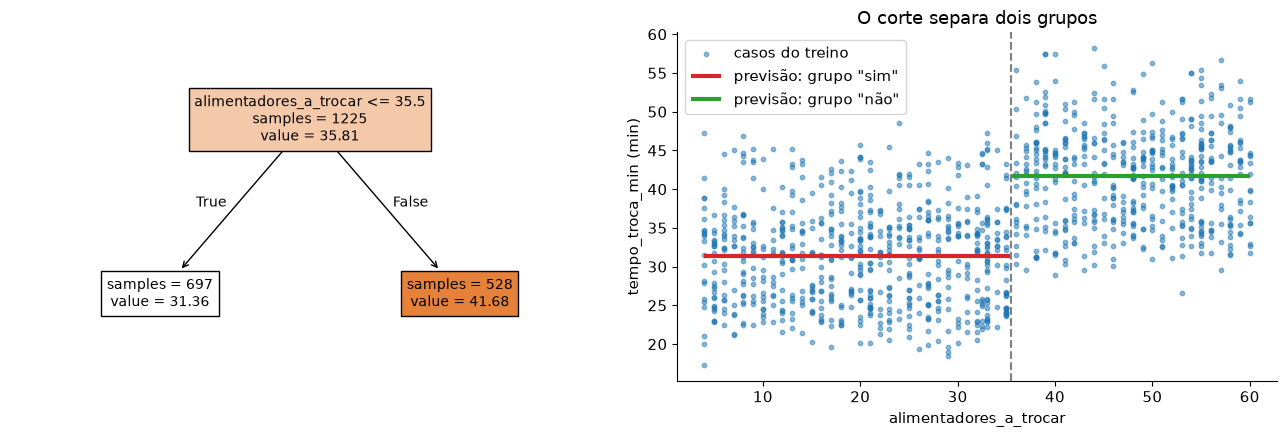

Pergunta: alimentadores_a_trocar <= 35.5?  Sim: prevê 31,36.  Não: prevê 41,68.
MAE da árvore de uma pergunta na validação: 4,76 (min).


In [11]:
CASAS = 2
entrada = 'alimentadores_a_trocar'
arvore_uma = DecisionTreeRegressor(max_depth=1, random_state=42)
arvore_uma.fit(X_treino[[entrada]], y_treino)
corte = arvore_uma.tree_.threshold[0]
prev_esq = arvore_uma.tree_.value[1][0][0]
prev_dir = arvore_uma.tree_.value[2][0][0]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
plot_tree(arvore_uma, feature_names=[entrada], filled=True, impurity=False, precision=max(CASAS, 1), fontsize=10, ax=ax1)
x = X_treino[entrada]
ax2.scatter(x, y_treino, s=10, alpha=0.5, label='casos do treino')
ax2.hlines(prev_esq, x.min(), corte, color='tab:red', linewidth=3, label='previsão: grupo "sim"')
ax2.hlines(prev_dir, corte, x.max(), color='tab:green', linewidth=3, label='previsão: grupo "não"')
ax2.axvline(corte, color='gray', linestyle='--')
ax2.set(xlabel=entrada, ylabel=f'{ALVO} ({UNIDADE_VALOR})', title='O corte separa dois grupos')
ax2.legend()
fig.tight_layout()
plt.show()

mae_uma = mean_absolute_error(y_val, arvore_uma.predict(X_val[[entrada]]))
print(f'Pergunta: {entrada} <= {corte:g}?  Sim: prevê {fmt(prev_esq)}.  Não: prevê {fmt(prev_dir)}.')
print(f'MAE da árvore de uma pergunta na validação: {fmt(mae_uma)} ({UNIDADE}).')

## 3.2 · Comparar árvores de uma pergunta com outras entradas

> **Por que importa:** Até agora oferecemos à árvore só `alimentadores_a_trocar`. Agora vamos experimentar **cada entrada, uma de cada vez**. Cada árvore aprende o seu corte usando o **treino**, e nós comparamos as previsões pelo **MAE na validação**.

São duas decisões diferentes:
- A **árvore** escolhe o corte pelo **erro ao quadrado no treino**.
- **Nós** comparamos as árvores pelo **MAE na validação**, que mede casos novos.

**De número para categoria.** Na animação, perguntamos se uma medida estava abaixo de um valor. Aqui também podemos perguntar se o caso pertence a uma categoria. As duas perguntas separam os casos em grupos. A tabela compara as colunas **depois do preparo**: `muda_familia_Sim` é uma pergunta específica ("muda de família?"), e não toda a informação da coluna original `muda_familia`.

O código abaixo repete, para todas as entradas, o que acabamos de fazer com `alimentadores_a_trocar`, e ordena da que mais ajuda para a que menos ajuda. Ninguém precisa testar coluna por coluna na mão.

**Palpite (antes de executar):** qual destas entradas vai errar menos? `alimentadores_a_trocar`, `kit_preparado_pct`, `experiencia_operador_meses`

In [12]:
linhas = []
for col in ENTRADAS:
    arv = DecisionTreeRegressor(max_depth=1, random_state=42).fit(X_treino[[col]], y_treino)
    corte_col = arv.tree_.threshold[0]
    linhas.append({'Entrada': col, 'Pergunta': f'{col} <= {corte_col:g}?',
                   'MAE validação': mean_absolute_error(y_val, arv.predict(X_val[[col]]))})
uma_pergunta = pd.DataFrame(linhas).sort_values('MAE validação').reset_index(drop=True)
display(uma_pergunta.round(CASAS))

,Entrada,Pergunta,MAE validação
0,alimentadores_a_trocar,alimentadores_a_trocar <= 35.5?,4.76
1,muda_familia_Não,muda_familia_Não <= 0.5?,5.47
2,muda_familia_Sim,muda_familia_Sim <= 0.5?,5.47
3,kit_preparado_pct,kit_preparado_pct <= 52.5?,5.86
4,linha_smt_SMT3,linha_smt_SMT3 <= 0.5?,5.97
5,linha_smt_SMT2,linha_smt_SMT2 <= 0.5?,6.02
6,componentes_novos,componentes_novos <= 2.5?,6.09
7,turno_Manhã,turno_Manhã <= 0.5?,6.10
8,turno_Noite,turno_Noite <= 0.5?,6.11
9,tamanho_lote_placas,tamanho_lote_placas <= 150?,6.12


> **Como ler a tabela:** cada linha é uma árvore de uma pergunta, usando **só aquela entrada**. A de cima errou menos na validação. Este ranking mostra o resultado de cada entrada **sozinha**, neste experimento: não é uma classificação definitiva de entradas boas e ruins, e uma entrada fraca sozinha pode ajudar quando combinada com outra. A tabela também não obriga que a primeira pergunta de uma árvore maior seja a primeira da tabela.

Agora desenhamos a árvore de uma pergunta com o **menor MAE** na validação.

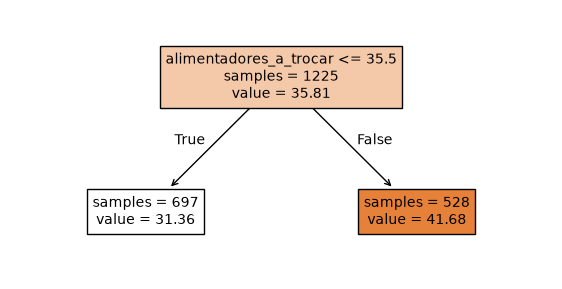

Melhor pergunta: alimentadores_a_trocar, erra 4,76.


In [13]:
melhor_uma = uma_pergunta.iloc[0]
entrada_melhor = melhor_uma['Entrada']
arvore_melhor = DecisionTreeRegressor(max_depth=1, random_state=42).fit(X_treino[[entrada_melhor]], y_treino)
fig, ax = plt.subplots(figsize=(7, 3.5))
plot_tree(arvore_melhor, feature_names=[entrada_melhor], filled=True, impurity=False, precision=max(CASAS, 1), fontsize=10, ax=ax)
plt.show()
print(f"Melhor pergunta: {entrada_melhor}, erra {fmt(melhor_uma['MAE validação'])}.")

**Como ler uma pergunta de coluna 0/1.** Na preparação, o texto virou colunas 0 e 1. Quando a pergunta é sobre uma dessas colunas, o corte `<= 0.5` separa o grupo com 0 (**não** é daquela categoria) do grupo com 1 (**é** daquela categoria). Funciona como o corte numérico: os casos são separados em dois grupos e cada grupo recebe a **média do treino** dele. Aqui, antes perguntávamos se o número de alimentadores estava abaixo de um valor; agora podemos perguntar se a troca muda de família de produto. Nos dois casos, separamos as trocas em grupos e prevemos a média de cada grupo.

### Notas (opcional)
Escreva livremente aqui. Algumas perguntas para ajudar:
- Qual árvore de uma pergunta teve o menor MAE?
- O resultado surpreendeu você?

**Notas:** A pergunta de uma entrada com menor MAE na validação está na tabela da seção 3.2.

## 3.3 · Experimentar uma profundidade

> **Por que importa:** Até aqui a árvore fez **uma** pergunta. Agora ela pode usar **todas** as entradas e fazer várias perguntas em sequência. **Você escolhe a profundidade permitida; a árvore escolhe as perguntas e os cortes usando o treino.** Profundidade 2 quer dizer que, no caminho de cada caso até a previsão, há **no máximo duas perguntas** (não duas perguntas na árvore inteira: cada ramo pode ter perguntas diferentes).

**Palpite:** permitir mais perguntas sempre melhora o resultado em casos novos?

### Sua vez 3 · Experimentar uma profundidade
Escreva a profundidade, crie a árvore e treine com o treino. Depois execute a célula seguinte, mude a profundidade (por exemplo, 1, 2 e 4) e execute **as duas células** de novo. Observe como mudam as perguntas, as folhas e os erros. Os desenhos mostram no máximo os 3 primeiros níveis da árvore, mas os erros usam a árvore inteira.

In [14]:
profundidade = 4

arvore_experimento = DecisionTreeRegressor(
    max_depth=profundidade,
    random_state=42
)
arvore_experimento.fit(X_treino, y_treino)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``

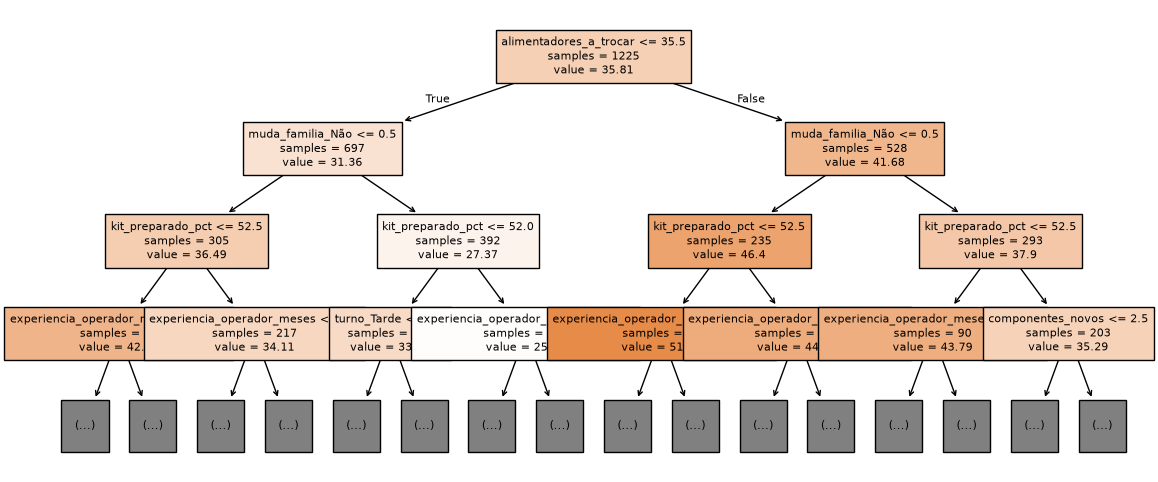

O desenho mostra só os 3 primeiros níveis; os erros abaixo usam a árvore inteira.
Profundidade experimentada: 4
MAE no treino:      1,98 (min)
MAE na validação:   2,04 (min)


In [15]:
if not (profundidade is None or (isinstance(profundidade, int) and profundidade >= 1)):
    raise ValueError('Confira a Sua vez 3: a profundidade deve ser um número inteiro a partir de 1 (ou None, para sem limite).')
fig, ax = plt.subplots(figsize=(14, 6))
plot_tree(arvore_experimento, max_depth=3, feature_names=ENTRADAS, filled=True, impurity=False, precision=max(CASAS, 1), fontsize=8, ax=ax)
plt.show()
if profundidade is None or profundidade > 3:
    print('O desenho mostra só os 3 primeiros níveis; os erros abaixo usam a árvore inteira.')
print('Profundidade experimentada:', 'sem limite' if profundidade is None else profundidade)
print(f"MAE no treino:      {fmt(mean_absolute_error(y_treino, arvore_experimento.predict(X_treino)))} ({UNIDADE})")
print(f"MAE na validação:   {fmt(mean_absolute_error(y_val, arvore_experimento.predict(X_val)))} ({UNIDADE})")

## 3.4 · Comparar várias profundidades

> **Por que importa:** Executar uma profundidade por vez é cansativo. O código abaixo **repete o que você acabou de fazer** para uma lista de profundidades. Ele usa os mesmos dados e as mesmas configurações do experimento individual, só que automático. `None` quer dizer **sem limite**.

In [16]:
PROFUNDIDADES = [1, 2, 4, 6, None]

linhas = []
for prof in PROFUNDIDADES:
    arv = DecisionTreeRegressor(max_depth=prof, random_state=42).fit(X_treino, y_treino)
    linhas.append({'Profundidade': 'sem limite' if prof is None else prof,
                   'MAE treino': mean_absolute_error(y_treino, arv.predict(X_treino)),
                   'MAE validação': mean_absolute_error(y_val, arv.predict(X_val))})
tabela = pd.DataFrame(linhas)
display(tabela.round(CASAS))

,Profundidade,MAE treino,MAE validação
0,1,5.22,4.76
1,2,3.73,3.57
2,4,1.98,2.04
3,6,1.77,2.18
4,sem limite,0.00,2.96


**Como ler o gráfico a seguir:**
- O eixo horizontal mostra as profundidades avaliadas.
- O eixo vertical mostra o MAE: **quanto menor, menor o erro**.
- A linha do **treino** mostra o resultado nos casos usados para aprender.
- A linha da **validação** mostra o resultado nos casos separados para comparar os modelos.

A profundidade escolhida é a do **menor ponto da linha da validação**.

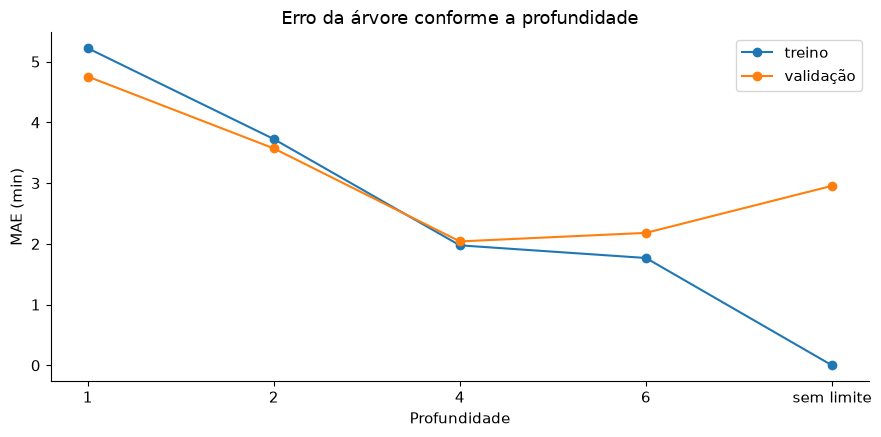

In [17]:
fig, ax = plt.subplots()
pos = range(len(tabela))
ax.plot(pos, tabela['MAE treino'], marker='o', label='treino')
ax.plot(pos, tabela['MAE validação'], marker='o', label='validação')
ax.set_xticks(list(pos), tabela['Profundidade'].astype(str))
ax.set(xlabel='Profundidade', ylabel=f'MAE ({UNIDADE})', title='Erro da árvore conforme a profundidade')
ax.legend()
fig.tight_layout()
plt.show()


**Tarefa:** identifique a profundidade com o menor MAE na validação. Depois observe se alguma árvore teve erro menor no treino e maior na validação.

> Quem decide a profundidade é sempre a validação: outras bases podem favorecer outras profundidades.

## 3.5 · Escolher a profundidade e ver a árvore final

> **Por que importa:** A escolha é feita **antes** de abrir o teste, usando só a validação. Erro baixo no treino mostra como o modelo se ajustou aos exemplos usados para aprender; a validação mostra como ele se comporta em casos novos.

### Sua vez 4 · Profundidade escolhida
Consulte a tabela e o gráfico e escreva a profundidade com o **menor MAE na validação** entre as testadas. Se for a opção sem limite, escreva `None`.

In [18]:
profundidade_escolhida = 4

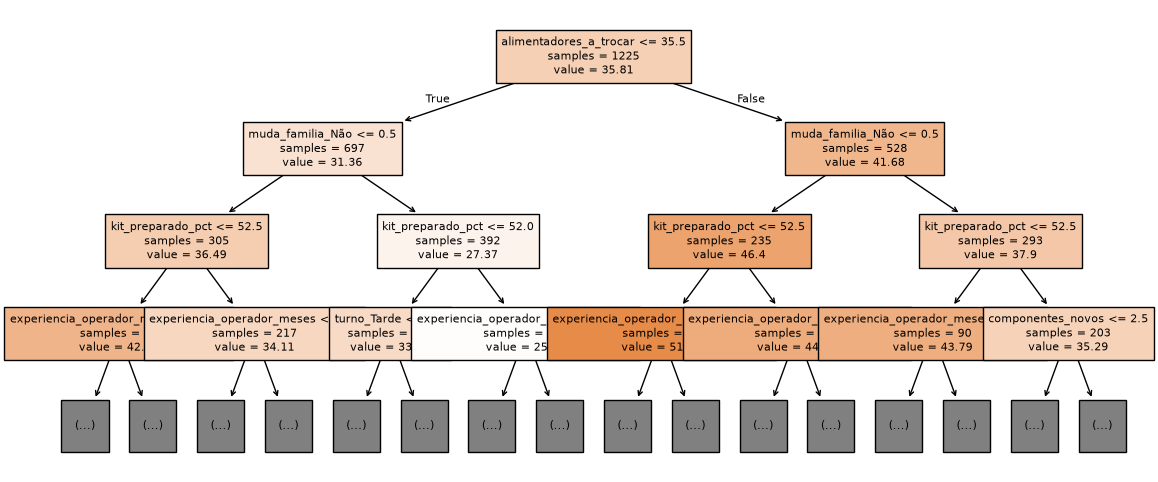

O desenho mostra só os 3 primeiros níveis; os erros abaixo usam a árvore inteira.
Árvore final: árvore de profundidade 4
MAE no treino:    1,98 (min)
MAE na validação: 2,04 (min)
Nas colunas 0/1, "<= 0.5" quer dizer "não".


In [19]:
arvore_final = DecisionTreeRegressor(max_depth=profundidade_escolhida, random_state=42)
arvore_final.fit(X_treino, y_treino)
nome_arvore = 'árvore sem limite' if profundidade_escolhida is None else f'árvore de profundidade {profundidade_escolhida}'
mae_escolhida = mean_absolute_error(y_val, arvore_final.predict(X_val))
fig, ax = plt.subplots(figsize=(14, 6))
plot_tree(arvore_final, max_depth=3, feature_names=ENTRADAS, filled=True, impurity=False, precision=max(CASAS, 1), fontsize=8, ax=ax)
plt.show()
if profundidade_escolhida is None or profundidade_escolhida > 3:
    print('O desenho mostra só os 3 primeiros níveis; os erros abaixo usam a árvore inteira.')
print('Árvore final:', nome_arvore)
print(f"MAE no treino:    {fmt(mean_absolute_error(y_treino, arvore_final.predict(X_treino)))} ({UNIDADE})")
print(f"MAE na validação: {fmt(mae_escolhida)} ({UNIDADE})")
print('Nas colunas 0/1, "<= 0.5" quer dizer "não".')

---
# 4 · Regressão linear: a reta

## 4.1 · Treinar, prever e avaliar

> **Por que importa:** Na animação, a previsão dependia de **uma** entrada. Agora, a conta pode **combinar várias informações** sobre cada caso. A árvore prevê por degraus (um valor por folha); a reta soma as entradas, cada uma multiplicada por um **coeficiente** aprendido no treino, e a previsão muda um pouco a cada mudança na entrada.

Aqui **não é preciso experimentar várias retas**: a função de treinamento calcula os coeficientes usando os dados de treino. Nesta atividade, não calculamos esses valores à mão. Os três passos são: **treinar** (no treino), **prever** (na validação) e **avaliar** (MAE).

**Complete as células abaixo:** primeiro informe as entradas e as respostas do treino; depois faça as previsões para as entradas da validação; por último, compare essas previsões com as respostas reais da validação.

**Palpite:** a reta vai errar mais ou menos do que a árvore escolhida? Depois de executar, confira se acertou.

In [20]:
reta = LinearRegression()
reta.fit(X_treino, y_treino)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](13,)","[ 0.26,-0.11,-0.01,...,-0.13,-0.05, 0.18]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](13,)","['alimentadores_a_trocar','kit_preparado_pct','experiencia_operador_meses', ...,'turno_Manhã','turno_Noite','turno_Tarde']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,34.07
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,13
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,10


In [21]:
previsto_reta = reta.predict(X_val)

In [22]:
mae_reta = mean_absolute_error(y_val, previsto_reta)
print(f'MAE da reta na validação: {fmt(mae_reta)} ({UNIDADE})')

MAE da reta na validação: 3,02 (min)


**Valores da reta (leitura opcional).** A previsão é `b0 + b1 × entrada1 + b2 × entrada2 + ...`. Abaixo estão os valores aprendidos no treino: `b0` é o valor inicial e cada entrada tem o seu `b`. **Cuidado:** um `b` maior não significa que a entrada é mais importante, porque as entradas têm escalas e unidades diferentes.

In [23]:
print(f'b0 (valor inicial): {reta.intercept_:.4g} ({UNIDADE_VALOR})')
display(pd.Series(reta.coef_, index=ENTRADAS, name='b').round(4).to_frame())

b0 (valor inicial): 34.07 (min)


,b
alimentadores_a_trocar,0.2624
kit_preparado_pct,-0.1081
experiencia_operador_meses,-0.0095
componentes_novos,0.3596
tamanho_lote_placas,0.0000
linha_smt_SMT1,0.2745
linha_smt_SMT2,-0.2544
linha_smt_SMT3,-0.0201
muda_familia_Não,-4.5151
muda_familia_Sim,4.5151


## 4.2 · Ver a reta no gráfico

> **Por que importa:** a reta do bloco 4 combina **várias** entradas, e um gráfico plano só mostra **uma** entrada de cada vez. Por isso o gráfico abaixo tem duas partes. **À esquerda:** uma reta com uma única entrada (a numérica mais ligada à resposta), aprendida no treino e desenhada sobre os **casos da validação**, só para enxergar a ideia da reta que passa no meio dos pontos. **À direita:** a reta do bloco 4 (todas as entradas), pronta, vista pelas previsões nos **dados de validação**: cada ponto é um caso da validação, e quanto mais perto da linha pontilhada, menor o erro.

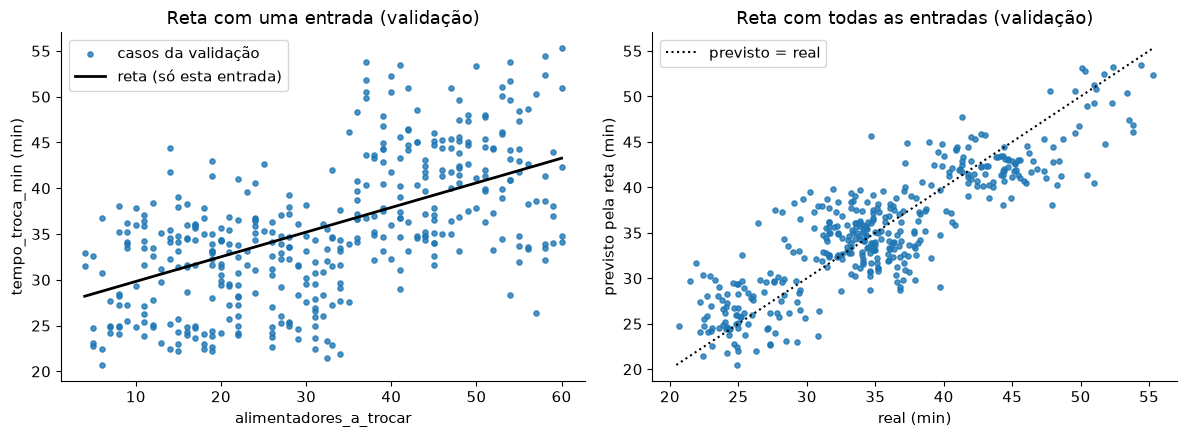

Esquerda: reta só com alimentadores_a_trocar (b0 = 27.13, b = 0.2692).


In [24]:
entrada_reta = X_treino[NUMERICAS].corrwith(y_treino).abs().idxmax()
reta_uma = LinearRegression().fit(X_treino[[entrada_reta]], y_treino)
xs = np.linspace(X_treino[entrada_reta].min(), X_treino[entrada_reta].max(), 100)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.scatter(X_val[entrada_reta], y_val, s=14, alpha=0.8, label='casos da validação')
ax1.plot(xs, reta_uma.predict(pd.DataFrame({entrada_reta: xs})), color='black', linewidth=2, label='reta (só esta entrada)')
ax1.set(xlabel=entrada_reta, ylabel=f'{ALVO} ({UNIDADE_VALOR})', title='Reta com uma entrada (validação)')
ax1.legend()
ax2.scatter(y_val, previsto_reta, s=14, alpha=0.8)
limites = [min(y_val.min(), previsto_reta.min()), max(y_val.max(), previsto_reta.max())]
ax2.plot(limites, limites, linestyle=':', color='black', label='previsto = real')
ax2.set(xlabel=f'real ({UNIDADE_VALOR})', ylabel=f'previsto pela reta ({UNIDADE_VALOR})', title='Reta com todas as entradas (validação)')
ax2.legend()
plt.tight_layout()
plt.show()
print(f'Esquerda: reta só com {entrada_reta} (b0 = {reta_uma.intercept_:.4g}, b = {reta_uma.coef_[0]:.4g}).')

---
# 5 · Comparação final

## 5.1 · Média, árvore e reta na validação

> **Por que importa:** As três formas são comparadas nos **mesmos casos de validação**. O teste só é aberto depois da escolha (seção 5.2).

In [25]:
comparacao = pd.DataFrame({'Forma': ['Média de referência', nome_arvore.capitalize(), 'Reta'],
                           'MAE validação': [mae_regua, mae_escolhida, mae_reta]})
display(comparacao.round(CASAS + 1))

,Forma,MAE validação
0,Média de referência,6.100
1,Árvore de profundidade 4,2.040
2,Reta,3.021


> **Como ler:** quando a diferença entre dois modelos é muito pequena, é um **empate prático**: com poucos casos de validação, não dá para afirmar que um é melhor que o outro. Nesse caso, a regra "menor MAE na validação" ainda indica um, mas vale pesar também simplicidade e o que faz sentido para o processo.



## 5.2 · Escolher o modelo e abrir o teste

> **Por que importa:** A escolha já foi feita com a validação. Agora o **teste** é aberto **uma única vez**, para ver como o modelo escolhido se comporta em casos que nunca participaram de nenhuma decisão. Depois de ver o resultado, **não volte para trocar o modelo**: isso transformaria o teste em mais uma validação. Você pode executar o notebook de novo para reproduzir os resultados; o que não se deve fazer é usar o resultado do teste para continuar experimentando e escolher outro modelo.

**Sua vez 5.** Olhe a tabela da seção 5.1 e escreva qual modelo você escolhe: `'media'`, `'arvore'` ou `'reta'`.

In [26]:
modelo_escolhido = 'arvore'

In [27]:
previsores = {'media': lambda X: np.full(len(X), media_treino),
              'arvore': arvore_final.predict,
              'reta': reta.predict}
if modelo_escolhido not in previsores:
    raise ValueError("Escreva 'media', 'arvore' ou 'reta' na célula anterior e rode de novo.")

previsto_teste = previsores[modelo_escolhido](X_teste)
mae_val_escolhido = mean_absolute_error(y_val, previsores[modelo_escolhido](X_val))

Agora calcule o **MAE no teste** do modelo escolhido, com os valores reais e as previsões do teste.

In [28]:
mae_teste = mean_absolute_error(y_teste, previsto_teste)
print(f'MAE na validação ({modelo_escolhido}): {fmt(mae_val_escolhido)} ({UNIDADE})')
print(f'MAE no teste ({modelo_escolhido}):     {fmt(mae_teste)} ({UNIDADE})')

MAE na validação (arvore): 2,04 (min)
MAE no teste (arvore):     1,93 (min)


> **Como ler:** o teste mostra o erro esperado em casos novos. Se o MAE no teste ficar perto do da validação, a escolha se sustenta. Se ficar bem maior, o modelo pode ter se ajustado demais ao que foi visto. Compare também o MAE no teste com a **tolerância** do enunciado: cabe ou não cabe?

## 5.3 · Testar um caso do teste
Escolha um caso do teste, entregue as entradas ao modelo e compare a previsão com o valor real. Troque o número e rode de novo para ver outros casos. Esse caso ajuda a entender uma previsão individual: o erro dele não substitui o MAE calculado com todos os casos do teste.

In [29]:
numero = 0   # troque por outro número, de 0 até len(teste) - 1
caso = teste.iloc[[numero]]
print(f'Caso {numero} do teste. Entradas:')
display(caso[NUMERICAS + CATEGORICAS].T.rename(columns={caso.index[0]: 'valor'}))
previsto_caso = previsores[modelo_escolhido](preparar(caso))[0]
real_caso = caso[ALVO].iloc[0]
print(f'Previsto ({modelo_escolhido}): {fmt(previsto_caso)} ({UNIDADE_VALOR})')
print(f'Real:                  {fmt(real_caso)} ({UNIDADE_VALOR})')
print(f'Erro (real − previsto): {fmt(real_caso - previsto_caso)} ({UNIDADE})')

Caso 0 do teste. Entradas:


,valor
alimentadores_a_trocar,11.0
kit_preparado_pct,25.0
experiencia_operador_meses,7.0
componentes_novos,0.0
tamanho_lote_placas,50.0
linha_smt,SMT3
muda_familia,Sim
turno,Tarde


Previsto (arvore): 44,62 (min)
Real:                  43,00 (min)
Erro (real − previsto): -1,62 (min)


## 5.4 · Salvar os resultados em um arquivo
A célula abaixo guarda em um arquivo `.json` os resultados desta aula: a divisão dos dados, o MAE da média, a tabela de profundidades, a profundidade escolhida, o MAE da árvore e da reta na validação, o modelo escolhido e o MAE no teste. Depois de executar, baixe o arquivo pelo painel **Arquivos** do Colab. Ele serve para retomar o trabalho na próxima aula e para a apresentação.

In [30]:
SAIDA = Path('resultados_N4')
SAIDA.mkdir(exist_ok=True)
ARQ = SAIDA / 'N4_regressao.json'
registro = {
    'alvo': ALVO, 'unidade': UNIDADE, 'estrategia_preenchimento': ESTRATEGIA,
    'divisao': resumo.astype(str).to_dict('index'),
    'mae_regua_validacao': round(float(mae_regua), 4),
    'melhor_uma_pergunta': str(melhor_uma['Entrada']),
    'tabela_profundidades': tabela.round(4).astype({'Profundidade': str}).to_dict('records'),
    'arvore_profundidade_escolhida': profundidade_escolhida,
    'arvore_mae_validacao': round(float(mae_escolhida), 4),
    'reta_mae_validacao': round(float(mae_reta), 4),
    'modelo_escolhido': modelo_escolhido,
    'mae_validacao_modelo_escolhido': round(float(mae_val_escolhido), 4),
    'mae_teste_modelo_escolhido': round(float(mae_teste), 4),
    'teste_aberto': True,
}
ARQ.write_text(json.dumps(registro, ensure_ascii=False, indent=2, default=str), encoding='utf-8')
print('Salvo em', ARQ.resolve(), '(baixe pelo painel Arquivos do Colab)')

Salvo em /home/pedro/SMT-Changeover-Prediction/entrega_N4/resultados_N4/N4_regressao.json (baixe pelo painel Arquivos do Colab)


## 5.5 · Conclusão

**Conclusão:**

Na validação, prever sempre a média do treino (35,81 min) errou em média 6,10 min. A reta errou 3,02 min e a árvore de profundidade 4 errou 2,04 min, a menor diferença para a média entre as três formas (a árvore errou cerca de um terço do erro da média). Escolhemos a **árvore de profundidade 4** porque teve o menor MAE na validação. A tabela de profundidades mostra que a árvore sem limite erra 0,00 min no treino e 2,96 min na validação, ou seja, decorou o treino e generaliza pior; a de profundidade 6 também ficou um pouco pior na validação (2,18 min) do que a de profundidade 4.

Com o teste aberto uma única vez, o modelo escolhido errou **1,93 min** em média. O valor ficou perto do da validação (2,04 min), então a escolha se sustenta e não há sinal de ajuste excessivo à validação. O MAE é uma média: no teste, 62 das 409 trocas (cerca de 15%) erraram mais de 3,5 min, e o maior erro foi de 8,52 min. No caso 0 do teste (troca de 43,00 min, com 11 alimentadores, kit 25% preparado e mudança de família), o modelo previu 44,62 min, um erro de 1,62 min.

A meta de erro do enunciado é de 3,5 min, e o modelo, com 1,93 min, **atende a ela**. A média de referência, com 6,10 min na validação, não atenderia. A meta é sobre o erro médio: este teste mostra que o erro médio está dentro do critério, mas não que cada previsão individual seja confiável. A base é a fornecida para o curso, então o resultado não garante o mesmo desempenho numa fábrica real, e a divisão por sorteio não mede o efeito de mudanças ao longo do tempo.

---
# Para saber mais (opcional)

**Média ou mediana.** O método da média usa `y_treino.mean()`. A mediana (`y_treino.median()`) também pode ser a previsão de referência: ela é o número que dá o menor erro absoluto, e a média dá o menor erro ao quadrado.

**Outro critério para a árvore.** O `DecisionTreeRegressor` usa por padrão o erro ao quadrado, e cada folha prevê a média. Com `criterion='absolute_error'`, usa o erro absoluto e cada folha prevê a mediana.